In [97]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [98]:
PROJECT_DIR = Path.home() / "ML_Project"
REPO_DIR = PROJECT_DIR / "github_data"

MODEL_PATH = REPO_DIR / "object_model.keras"
TEST_DIR = REPO_DIR / "dataset" / "test"
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "apple",
    "glass_container",
    "oranges",
    "popcorn",
    "water_bottle"
]

print("Model path:", MODEL_PATH)
print("Test directory:", TEST_DIR)
print("Classes:", CLASS_NAMES)

Model path: /home/himanshu/ML_Project/github_data/object_model.keras
Test directory: /home/himanshu/ML_Project/github_data/dataset/test
Classes: ['apple', 'glass_container', 'oranges', 'popcorn', 'water_bottle']


In [99]:
model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully!")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

Model loaded successfully!
Input shape: (None, 128, 128, 3)
Output shape: (None, 5)


In [100]:
test_data = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=(128, 128),
    batch_size=32,
    shuffle=False
)

print("Class order:", test_data.class_names)

Found 78 files belonging to 5 classes.
Class order: ['apple', 'glass_container', 'oranges', 'popcorn', 'water_bottle']


In [101]:
y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_data
])

y_prob = model.predict(test_data, verbose=1)

y_pred = np.argmax(y_prob, axis=1)

print("Actual labels:", y_true.shape)
print("Predictions:", y_pred.shape)
print("Prediction Scores:", y_prob.shape)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
Actual labels: (78,)
Predictions: (78,)
Prediction Scores: (78, 5)


In [102]:
accuracy = accuracy_score(y_true, y_pred)

correct = int(np.sum(y_true == y_pred))
incorrect = int(np.sum(y_true != y_pred))

print(f"Total test images: {len(y_true)}")
print(f"Correct predictions: {correct}")
print(f"Incorrect predictions: {incorrect}")
print(f"Test accuracy: {accuracy:.2%}")

Total test images: 78
Correct predictions: 66
Incorrect predictions: 12
Test accuracy: 84.62%


In [103]:
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    zero_division=0
)

print(report)

report_path = RESULTS_DIR / "classification_report.txt"
report_path.write_text(report)

print("Report saved to:", report_path)

                 precision    recall  f1-score   support

          apple       0.79      0.83      0.81        18
glass_container       0.72      0.87      0.79        15
        oranges       1.00      0.80      0.89        15
        popcorn       0.87      0.87      0.87        15
   water_bottle       0.93      0.87      0.90        15

       accuracy                           0.85        78
      macro avg       0.86      0.85      0.85        78
   weighted avg       0.86      0.85      0.85        78

Report saved to: /home/himanshu/ML_Project/results/classification_report.txt


Confusion Matrix:
[[15  1  0  2  0]
 [ 1 13  0  0  1]
 [ 2  1 12  0  0]
 [ 1  1  0 13  0]
 [ 0  2  0  0 13]]


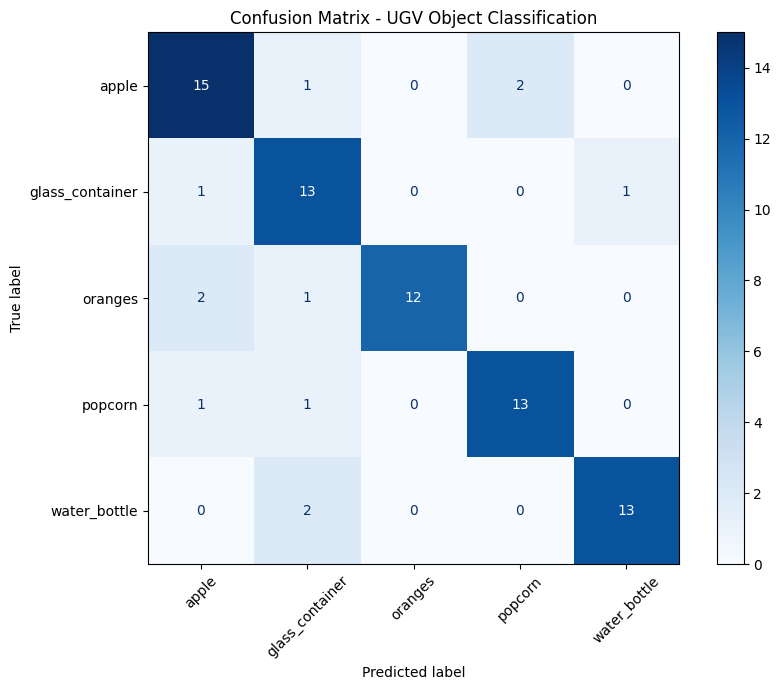

In [107]:
cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

fig, ax = plt.subplots(figsize=(9, 7))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Confusion Matrix - UGV Object Classification")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=300)
plt.show()

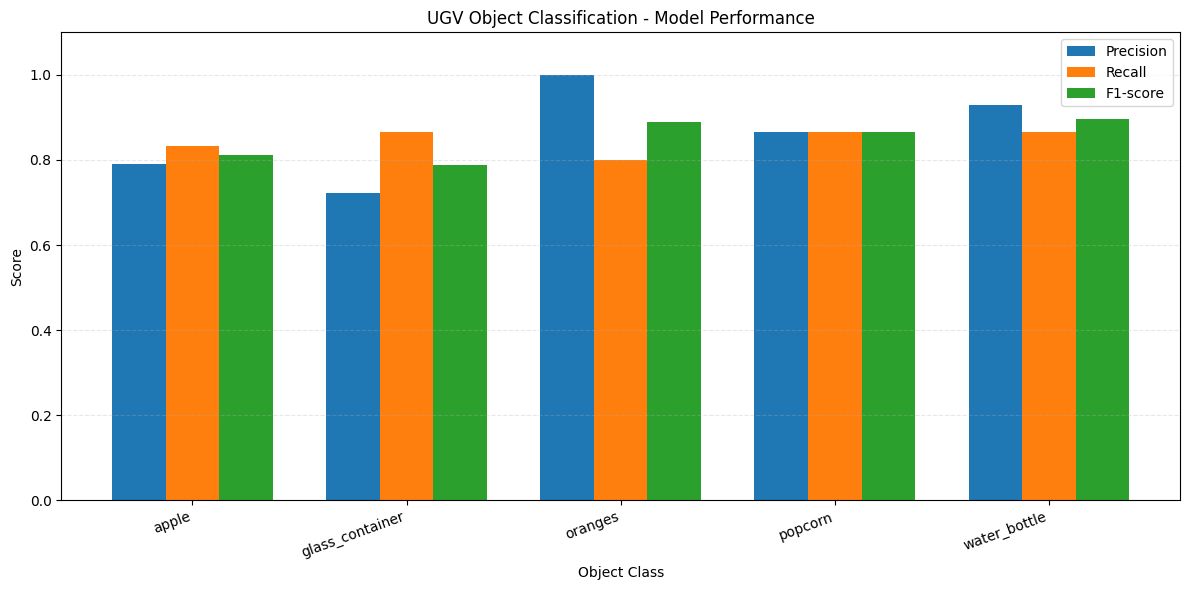

Graph saved to: /home/himanshu/ML_Project/results/class_performance.png


In [110]:
# Calculate metrics for each class
precision, recall, f1, support = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=range(len(CLASS_NAMES)),
    zero_division=0
)

# Set positions for the bars
x = np.arange(len(CLASS_NAMES))
width = 0.25

# Create the graph
fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(x - width, precision, width, label="Precision")
ax.bar(x, recall, width, label="Recall")
ax.bar(x + width, f1, width, label="F1-score")

# Format the graph
ax.set_title("UGV Object Classification - Model Performance")
ax.set_xlabel("Object Class")
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=20, ha="right")
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()

# Save the graph
plt.savefig(RESULTS_DIR / "class_performance.png", dpi=300)
plt.show()

print("Graph saved to:", RESULTS_DIR / "class_performance.png")

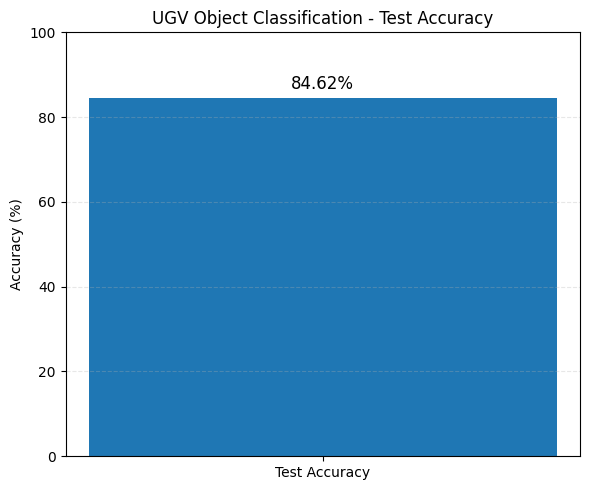

Test accuracy: 84.62%


In [111]:
accuracy = np.mean(y_true == y_pred) * 100

fig, ax = plt.subplots(figsize=(6, 5))

ax.bar(["Test Accuracy"], [accuracy])

ax.set_title("UGV Object Classification - Test Accuracy")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)

ax.text(
    0,
    accuracy + 2,
    f"{accuracy:.2f}%",
    ha="center",
    fontsize=12
)

ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()

plt.savefig(RESULTS_DIR / "test_accuracy.png", dpi=300)
plt.show()

print(f"Test accuracy: {accuracy:.2f}%")

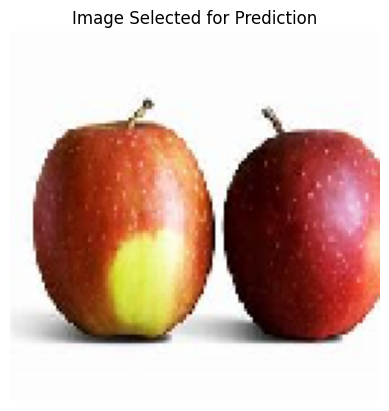

Image shape: (128, 128, 3)


In [117]:
from tensorflow.keras.utils import load_img, img_to_array
import matplotlib.pyplot as plt

img = load_img(image_path, target_size=(128, 128))
img_array = img_to_array(img)

plt.imshow(img)
plt.title("Image Selected for Prediction")
plt.axis("off")
plt.show()

print("Image shape:", img_array.shape)

In [118]:
import numpy as np

# Add a batch dimension to the image
input_batch = np.expand_dims(img_array, axis=0)

# Predict the class
probabilities = model.predict(input_batch, verbose=0)[0]
predicted_index = int(np.argmax(probabilities))

print("Predicted class:", CLASS_NAMES[predicted_index])
print(f"Confidence: {probabilities[predicted_index] * 100:.2f}%")
print("Actual class: apple")

Predicted class: apple
Confidence: 99.96%
Actual class: apple


In [133]:
from pathlib import Path

TEST_DIR = Path.home() / "ML_Project" / "github_data" / "dataset" / "test"

# Select an image from the glass_container class
image_folder = TEST_DIR / "glass_container"

images = (
    list(image_folder.glob("*.jpg"))
    + list(image_folder.glob("*.jpeg"))
    + list(image_folder.glob("*.png"))
)

print("Images found:", len(images))

if images:
    image_path = images[0]
    print("Selected image:", image_path)
else:
    print("No images found. Check the folder and image formats.")

Images found: 15
Selected image: /home/himanshu/ML_Project/github_data/dataset/test/glass_container/0.bing.glass_container.141.jpg


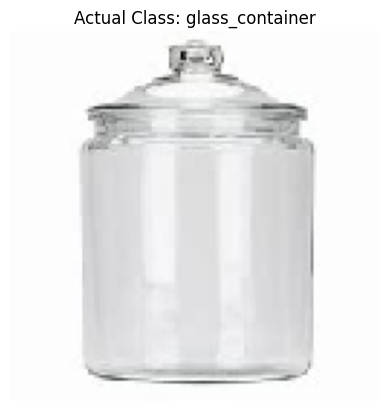

In [134]:
from tensorflow.keras.utils import load_img, img_to_array
import matplotlib.pyplot as plt

img = load_img(image_path, target_size=(128, 128))
img_array = img_to_array(img)

plt.imshow(img)
plt.title("Actual Class: glass_container")
plt.axis("off")
plt.show()

In [136]:
from pathlib import Path

TEST_DIR = Path.home() / "ML_Project" / "github_data" / "dataset" / "test"
image_folder = TEST_DIR / "oranges"

images = (
    list(image_folder.glob("*.jpg"))
    + list(image_folder.glob("*.jpeg"))
    + list(image_folder.glob("*.png"))
)

print("Images found:", len(images))

if images:
    image_path = images[0]
    print("Selected image:", image_path)
else:
    print("No images found. Check the folder and image formats.")

Images found: 15
Selected image: /home/himanshu/ML_Project/github_data/dataset/test/oranges/0.bing.Oranges+fruit.150.jpg


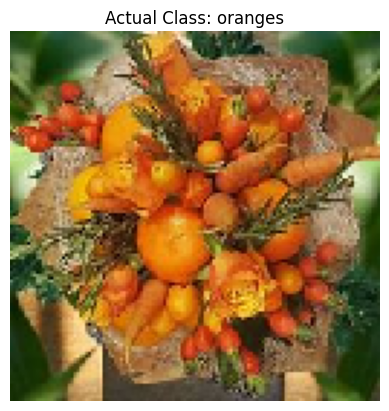

In [137]:
from tensorflow.keras.utils import load_img, img_to_array
import matplotlib.pyplot as plt

img = load_img(image_path, target_size=(128, 128))
img_array = img_to_array(img)

plt.imshow(img)
plt.title("Actual Class: oranges")
plt.axis("off")
plt.show()

In [140]:
from pathlib import Path

TEST_DIR = Path.home() / "ML_Project" / "github_data" / "dataset" / "test"
image_folder = TEST_DIR / "popcorn"

images = (
    list(image_folder.glob("*.jpg"))
    + list(image_folder.glob("*.jpeg"))
    + list(image_folder.glob("*.png"))
)

print("Images found:", len(images))

if images:
    image_path = images[0]
    print("Selected image:", image_path)
else:
    print("No images found. Check the folder and image formats.")

Images found: 15
Selected image: /home/himanshu/ML_Project/github_data/dataset/test/popcorn/0.bing.Popcorn.66.jpg


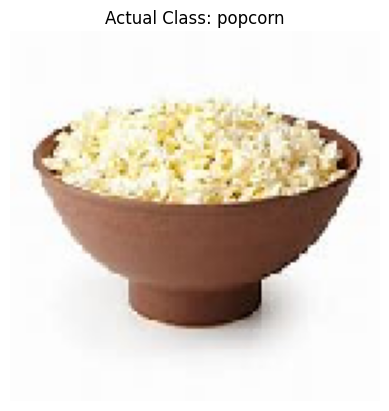

In [141]:
from tensorflow.keras.utils import load_img, img_to_array
import matplotlib.pyplot as plt

img = load_img(image_path, target_size=(128, 128))
img_array = img_to_array(img)

plt.imshow(img)
plt.title("Actual Class: popcorn")
plt.axis("off")
plt.show()

In [142]:
input_batch = np.expand_dims(img_array, axis=0)

probabilities = model.predict(input_batch, verbose=0)[0]
predicted_index = int(np.argmax(probabilities))

print("Predicted class:", CLASS_NAMES[predicted_index])
print(f"Confidence: {probabilities[predicted_index] * 100:.2f}%")
print("Actual class: popcorn")

Predicted class: popcorn
Confidence: 79.89%
Actual class: popcorn


In [143]:
from pathlib import Path

TEST_DIR = Path.home() / "ML_Project" / "github_data" / "dataset" / "test"
image_folder = TEST_DIR / "water_bottle"

images = (
    list(image_folder.glob("*.jpg"))
    + list(image_folder.glob("*.jpeg"))
    + list(image_folder.glob("*.png"))
)

print("Images found:", len(images))

if images:
    image_path = images[0]
    print("Selected image:", image_path)
else:
    print("No images found. Check the folder and image formats.")

Images found: 15
Selected image: /home/himanshu/ML_Project/github_data/dataset/test/water_bottle/0.bing.Mineral_Water.81.jpg


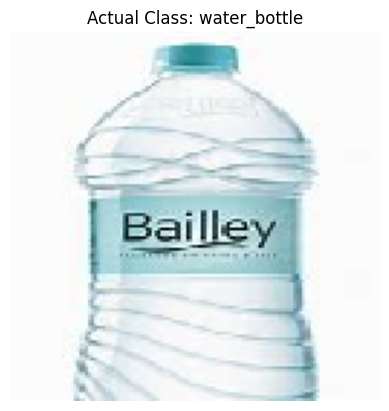

In [144]:
from tensorflow.keras.utils import load_img, img_to_array
import matplotlib.pyplot as plt

img = load_img(image_path, target_size=(128, 128))
img_array = img_to_array(img)

plt.imshow(img)
plt.title("Actual Class: water_bottle")
plt.axis("off")
plt.show()

In [145]:
input_batch = np.expand_dims(img_array, axis=0)

probabilities = model.predict(input_batch, verbose=0)[0]
predicted_index = int(np.argmax(probabilities))

print("Predicted class:", CLASS_NAMES[predicted_index])
print(f"Confidence: {probabilities[predicted_index] * 100:.2f}%")
print("Actual class: water_bottle")

Predicted class: water_bottle
Confidence: 99.97%
Actual class: water_bottle
